# MoveSense
MoveSense analyses automobile trip records to identify different urban mobility patterns. It groups trips with similar travel characteristics using K-Means clustering.

This is an unsupervised learning problem because the dataset does not contain predefined cluster labels.

How K-Means works:
1. Select the number of clusters, K.
2. Initialize K centroids.
3. Assign each trip to its nearest centroid.
4. Recalculate the centroids.
5. Repeat until the clusters stabilize.

# Dataset Information

In [1]:
from google.colab import files
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Upload dataset
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("Please upload the NHTS automobile trip CSV.")

filename = next(iter(uploaded))

df_raw = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    low_memory=False
)

print("Dataset:", filename)
print("Total Rows:", len(df_raw))
print("Total Columns:", len(df_raw.columns))

display(df_raw.head())

Saving MoveSense_NHTS_Automobile_Trips.csv to MoveSense_NHTS_Automobile_Trips.csv
Dataset: MoveSense_NHTS_Automobile_Trips.csv
Total Rows: 27360
Total Columns: 102


,HOUSEID,PERSONID,TRIPID,SEQ_TRIPID,VEHCASEID,FRSTHM,PARK,HHMEMDRV,TDWKND,TRAVDAY,...,OBHTNRNT,OBPPOPDN,OBRESDN,DTHTNRNT,DTPPOPDN,DTRESDN,DTEEMPDN,DBHTNRNT,DBPPOPDN,DBRESDN
0,9000013002,1,1,1,900001300201,1,2,1,1,1,...,5,4,3,5,5,3,6,5,4,3
1,9000013002,1,2,2,900001300201,1,2,1,1,1,...,5,4,3,20,4,2,5,5,4,3
2,9000013002,2,1,1,900001300202,1,-1,1,1,1,...,5,4,3,40,5,4,6,60,4,3
3,9000013002,2,2,2,900001300202,1,-1,1,1,1,...,60,4,3,5,3,2,4,5,3,2
4,9000013002,2,3,3,900001300202,1,-1,1,1,1,...,5,3,2,20,4,2,5,5,4,3


# Dataset Selection and Cleaning
We select automobile trips using TRIPMODE values 1 and 2, as configured in the current MoveSense backend for the NHTS V2.1 subset.

We then select distance, duration, and departure time and remove invalid records.

In [2]:
# Check required columns
required = ["TRIPMODE", "TRPMILES", "TRVLCMIN", "STRTTIME"]

missing = [col for col in required if col not in df_raw.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df_raw.copy()

# Convert required fields to numeric
for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Select automobile trips
print("Mode counts before filtering:")
print(df["TRIPMODE"].value_counts(dropna=False))

df = df[df["TRIPMODE"].isin([1, 2])].copy()

# Convert HHMM start time to departure hour
raw_time = df["STRTTIME"]

valid_time = (
    raw_time.between(0, 2359)
    & ((raw_time % 100) < 60)
)

df["departure_hour"] = np.where(
    valid_time,
    np.floor(raw_time / 100),
    np.nan
)

# Remove invalid trip records
df = df[
    df["TRPMILES"].notna()
    & df["TRVLCMIN"].notna()
    & df["departure_hour"].notna()
    & (df["TRPMILES"] > 0)
    & (df["TRPMILES"] < 1000)
    & (df["TRVLCMIN"] > 0)
    & (df["TRVLCMIN"] < 1440)
].copy()

df["departure_hour"] = df["departure_hour"].astype(int)

print("\nValid automobile trips:", len(df))

display(
    df[["TRPMILES", "TRVLCMIN", "STRTTIME", "departure_hour"]].head()
)

Mode counts before filtering:
TRIPMODE
1    20456
2     6904
Name: count, dtype: int64

Valid automobile trips: 27360


,TRPMILES,TRVLCMIN,STRTTIME,departure_hour
0,3.902424,15,1435,14
1,3.902424,10,1605,16
2,17.077067,30,700,7
3,4.748291,10,740,7
4,14.098819,30,800,8


# Feature Selection
K-Means requires numerical input. We use four features:

Feature	Description
*   distance_miles - Distance travelled
*   travel_time_min -	Duration of the trip
*   departure_hour -	Hour at which the trip begins
*   peak_hour_flag -	Indicates whether the trip starts during peak hours


Peak-hour windows: 7–9 AM and 4–6 PM.

In [3]:
# Identify peak-hour trips
peak_hours = [7, 8, 9, 16, 17, 18]

df["peak_hour_flag"] = (
    df["departure_hour"].isin(peak_hours)
).astype(int)

# Select model features
features = [
    "TRPMILES",
    "TRVLCMIN",
    "departure_hour",
    "peak_hour_flag"
]

X = df[features].copy()

# Rename for readability
X.columns = [
    "distance_miles",
    "travel_time_min",
    "departure_hour",
    "peak_hour_flag"
]

print("Selected Features:")
print(X.columns.tolist())

print("\nFeature Matrix Shape:", X.shape)

display(X.head())

Selected Features:
['distance_miles', 'travel_time_min', 'departure_hour', 'peak_hour_flag']

Feature Matrix Shape: (27360, 4)


,distance_miles,travel_time_min,departure_hour,peak_hour_flag
0,3.902424,15,14,0
1,3.902424,10,16,1
2,17.077067,30,7,1
3,4.748291,10,7,1
4,14.098819,30,8,1


# Feature Scaling
The features have different units and ranges. For example, distance is measured in miles, while duration is measured in minutes.

We use StandardScaler to standardize the features before applying K-Means.

In [4]:
# Standardize features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Feature Shape:", X.shape)
print("Scaled Feature Shape:", X_scaled.shape)

print("\nScaled Data Preview:")
display(pd.DataFrame(
    X_scaled,
    columns=X.columns
).head())

Original Feature Shape: (27360, 4)
Scaled Feature Shape: (27360, 4)

Scaled Data Preview:


,distance_miles,travel_time_min,departure_hour,peak_hour_flag
0,-0.238015,-0.202760,0.203300,-0.827797
1,-0.238015,-0.319855,0.677352,1.208026
2,0.151254,0.148524,-1.455881,1.208026
3,-0.213022,-0.319855,-1.455881,1.208026
4,0.063256,0.148524,-1.218855,1.208026


# K-Means Model Training
We test different values of K, from 2 to 8.

Two evaluation measurements are used:
- Inertia (WCSS): Measures how close the trips are to their assigned cluster centroids. Lower is better.
- Silhouette Score: Measures how well-separated the clusters are. Higher is generally better.

In [5]:
# K-Means parameter configuration
K_VALUES = range(2, 9)

INIT = "k-means++"
N_INIT = 20
MAX_ITER = 300
RANDOM_STATE = 42

results = []
models = {}

# Train models for different K values
for k in K_VALUES:

    model = KMeans(
        n_clusters=k,
        init=INIT,
        n_init=N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_STATE
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=RANDOM_STATE
    )

    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": score
    })

    models[k] = model

# Store evaluation results
evaluation_df = pd.DataFrame(results)

display(evaluation_df.round(4))

# Select K with highest silhouette score
best_k = int(
    evaluation_df.loc[
        evaluation_df["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Best K:", best_k)

,K,Inertia,Silhouette Score
0,2,77330.0384,0.8640
1,3,50091.6223,0.4786
2,4,37285.2056,0.5455
3,5,29256.1721,0.5942
4,6,21306.9177,0.6108
5,7,17827.8276,0.6244
6,8,14853.7324,0.6322


Best K: 2


# Final Model Training
After selecting K, we train the final K-Means model and assign every automobile trip to a cluster.

Model Parameters

*   K values: 2-8
*   Initialization: K-Means++
*   Number of initializations: 20
*   Maximum iterations: 300
*   Random State: 42
*   Scaling: StandardScaler







In [6]:
# Train final K-Means model
final_model = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=20,
    max_iter=300,
    random_state=42
)

cluster_labels = final_model.fit_predict(X_scaled)

# Add cluster labels to dataset
df["cluster"] = cluster_labels

# Calculate final evaluation metrics
final_silhouette = silhouette_score(
    X_scaled,
    cluster_labels,
    sample_size=min(5000, len(X_scaled)),
    random_state=42
)

print("FINAL MODEL RESULTS")
print("-------------------")
print("Selected K:", best_k)
print("Total Trips:", len(df))
print("Silhouette Score:", round(final_silhouette, 4))
print("Inertia:", round(final_model.inertia_, 2))

display(df.head())

FINAL MODEL RESULTS
-------------------
Selected K: 2
Total Trips: 27360
Silhouette Score: 0.864
Inertia: 77330.04


,HOUSEID,PERSONID,TRIPID,SEQ_TRIPID,VEHCASEID,FRSTHM,PARK,HHMEMDRV,TDWKND,TRAVDAY,...,DTHTNRNT,DTPPOPDN,DTRESDN,DTEEMPDN,DBHTNRNT,DBPPOPDN,DBRESDN,departure_hour,peak_hour_flag,cluster
0,9000013002,1,1,1,900001300201,1,2,1,1,1,...,5,5,3,6,5,4,3,14,0,1
1,9000013002,1,2,2,900001300201,1,2,1,1,1,...,20,4,2,5,5,4,3,16,1,1
2,9000013002,2,1,1,900001300202,1,-1,1,1,1,...,40,5,4,6,60,4,3,7,1,1
3,9000013002,2,2,2,900001300202,1,-1,1,1,1,...,5,3,2,4,5,3,2,7,1,1
4,9000013002,2,3,3,900001300202,1,-1,1,1,1,...,20,4,2,5,5,4,3,8,1,1


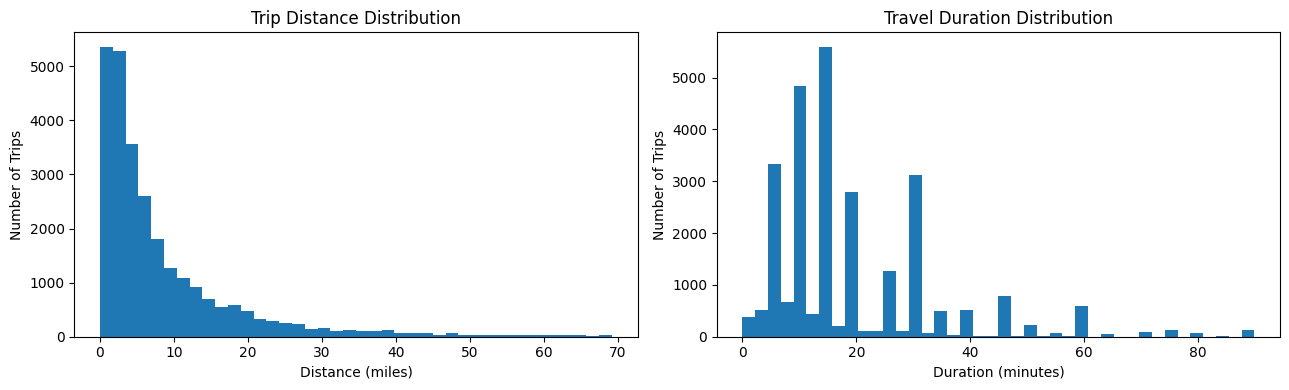

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Distance distribution
axes[0].hist(
    df["TRPMILES"],
    bins=40,
    range=(0, df["TRPMILES"].quantile(0.98))
)

axes[0].set_title("Trip Distance Distribution")
axes[0].set_xlabel("Distance (miles)")
axes[0].set_ylabel("Number of Trips")

# Duration distribution
axes[1].hist(
    df["TRVLCMIN"],
    bins=40,
    range=(0, df["TRVLCMIN"].quantile(0.98))
)

axes[1].set_title("Travel Duration Distribution")
axes[1].set_xlabel("Duration (minutes)")
axes[1].set_ylabel("Number of Trips")

plt.tight_layout()
plt.show()

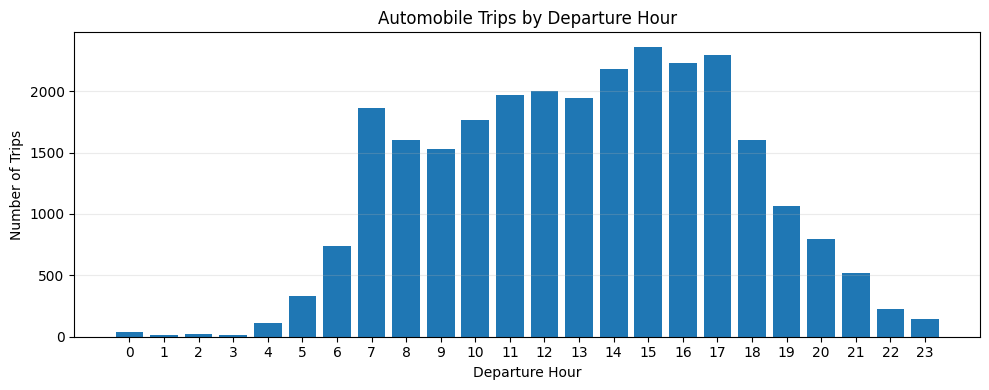

In [8]:
hour_counts = df["departure_hour"].value_counts().sort_index()

plt.figure(figsize=(10, 4))

plt.bar(
    hour_counts.index,
    hour_counts.values
)

plt.xticks(range(24))

plt.title("Automobile Trips by Departure Hour")
plt.xlabel("Departure Hour")
plt.ylabel("Number of Trips")

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

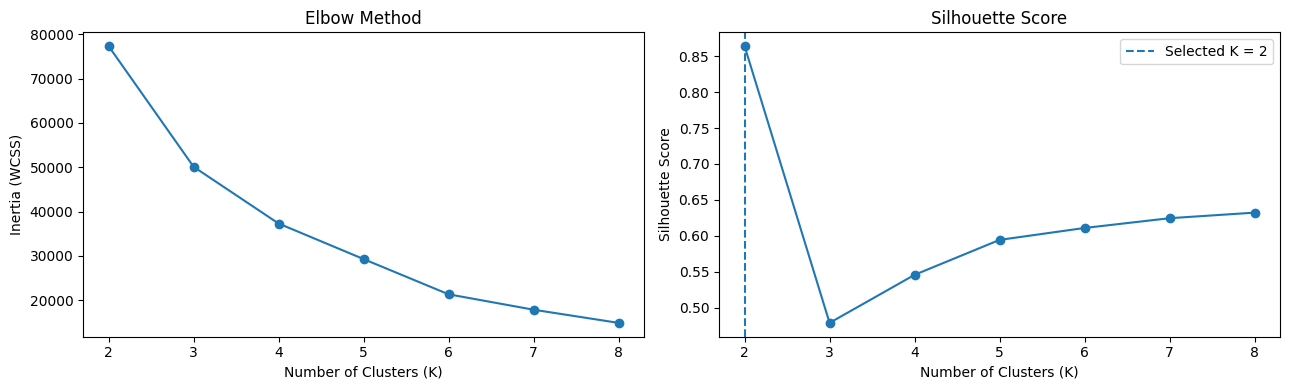

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Elbow Method
axes[0].plot(
    evaluation_df["K"],
    evaluation_df["Inertia"],
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (WCSS)")

# Silhouette Score
axes[1].plot(
    evaluation_df["K"],
    evaluation_df["Silhouette Score"],
    marker="o"
)

axes[1].axvline(
    best_k,
    linestyle="--",
    label=f"Selected K = {best_k}"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

plt.tight_layout()
plt.show()

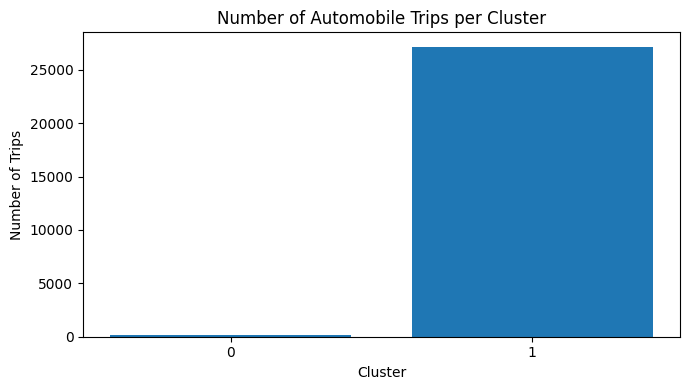

Cluster Distribution:


,count
cluster,
0,197
1,27163


In [10]:
cluster_counts = df["cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 4))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Number of Automobile Trips per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.show()

print("Cluster Distribution:")
display(cluster_counts)

In [11]:
profile = df.groupby("cluster").agg(
    trip_count=("cluster", "size"),
    avg_distance_miles=("TRPMILES", "mean"),
    avg_duration_min=("TRVLCMIN", "mean"),
    avg_departure_hour=("departure_hour", "mean"),
    peak_hour_share=("peak_hour_flag", "mean")
)

profile["trip_share"] = (
    profile["trip_count"] / len(df)
)

display(profile.round(2))

,trip_count,avg_distance_miles,avg_duration_min,avg_departure_hour,peak_hour_share,trip_share
cluster,,,,,,
0,197,313.05,410.81,10.24,0.41,0.01
1,27163,9.77,20.85,13.16,0.41,0.99


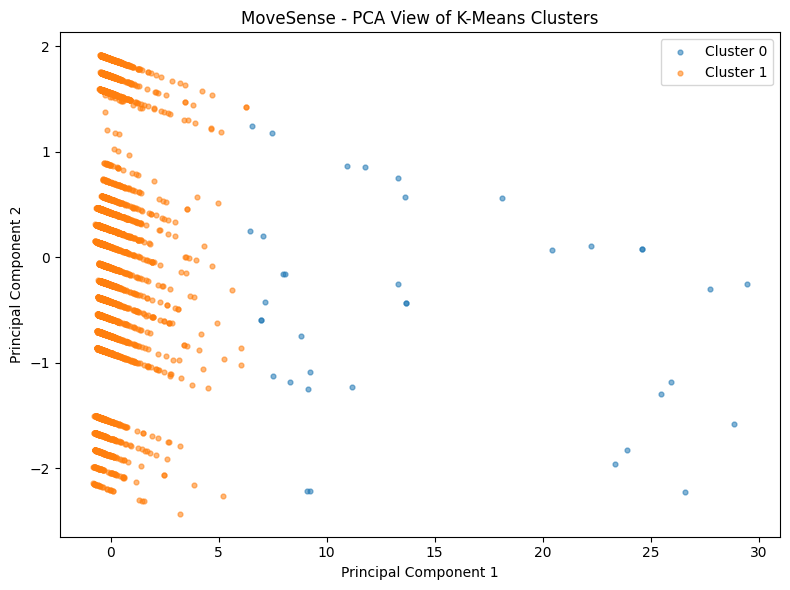

Variance explained by two PCA components: 72.88 %


In [12]:
# Apply PCA for 2D visualization
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

# Sample points for easier visualization
rng = np.random.RandomState(42)

plot_n = min(6000, len(X_pca))

sample_idx = rng.choice(
    len(X_pca),
    size=plot_n,
    replace=False
)

plt.figure(figsize=(8, 6))

for cluster_id in sorted(np.unique(cluster_labels)):

    mask = (
        cluster_labels[sample_idx] == cluster_id
    )

    plt.scatter(
        X_pca[sample_idx][mask, 0],
        X_pca[sample_idx][mask, 1],
        s=12,
        alpha=0.55,
        label=f"Cluster {cluster_id}"
    )

plt.title("MoveSense - PCA View of K-Means Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.tight_layout()
plt.show()

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

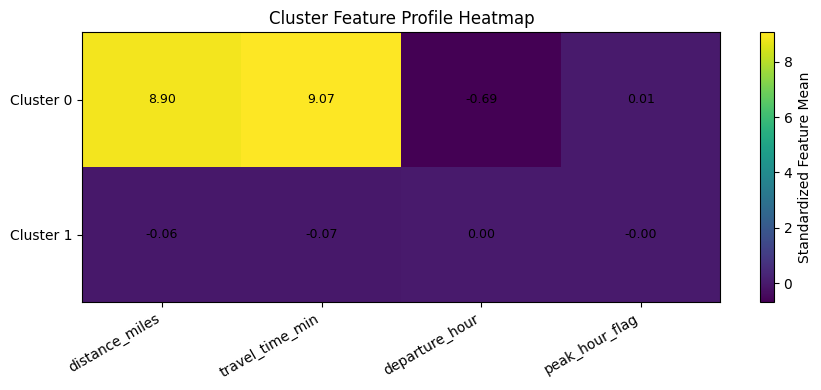

In [13]:
# Create scaled feature dataframe
scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=df.index
)

scaled_df["cluster"] = cluster_labels

# Calculate cluster feature means
cluster_means = (
    scaled_df.groupby("cluster")[X.columns].mean()
)

fig, ax = plt.subplots(figsize=(9, 4))

im = ax.imshow(
    cluster_means,
    aspect="auto"
)

ax.set_xticks(range(len(X.columns)))
ax.set_xticklabels(
    X.columns,
    rotation=30,
    ha="right"
)

ax.set_yticks(range(len(cluster_means.index)))
ax.set_yticklabels(
    [f"Cluster {c}" for c in cluster_means.index]
)

ax.set_title("Cluster Feature Profile Heatmap")

fig.colorbar(
    im,
    ax=ax,
    label="Standardized Feature Mean"
)

for row in range(cluster_means.shape[0]):
    for col in range(cluster_means.shape[1]):

        ax.text(
            col,
            row,
            f"{cluster_means.iloc[row, col]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.tight_layout()
plt.show()